In [2]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load pre-generated robustness results
df_results = pd.read_csv("data/sensor_robustness_results.csv")
print("Data loaded successfully!")
display(df_results.head())

# Load baseline model metrics
with open("models/model_metrics_random_forest.json", "r") as f:
    baseline_metrics = json.load(f)

print("Baseline Metrics:", baseline_metrics)

Data loaded successfully!


,noise_level,fault_type,accuracy,precision,recall,f1_score,mae
0,5,Baseline (Clean),0.998843,0.963636,0.990654,0.976959,0.001157
1,5,Gaussian (EMI),0.992824,0.827586,0.897196,0.860987,0.007176
2,5,Impulse (Spikes),0.995370,0.899083,0.915888,0.907407,0.004630
3,5,Sensor Drift (Silt),0.977546,1.000000,0.093458,0.170940,0.022454
4,5,Freezing (Stuck),0.966898,0.320000,0.299065,0.309179,0.033102


Baseline Metrics: {'model': 'random_forest', 'accuracy': 0.9953703703703703, 'precision': 0.8695652173913043, 'recall': 0.9523809523809523, 'f1_score': 0.9090909090909091}


In [3]:
import joblib

# Load trained model directly
rf_model = joblib.load("models/gate_model_random_forest.joblib")
print("Model loaded into notebook memory:", type(rf_model))

Model loaded into notebook memory: <class 'sklearn.pipeline.Pipeline'>


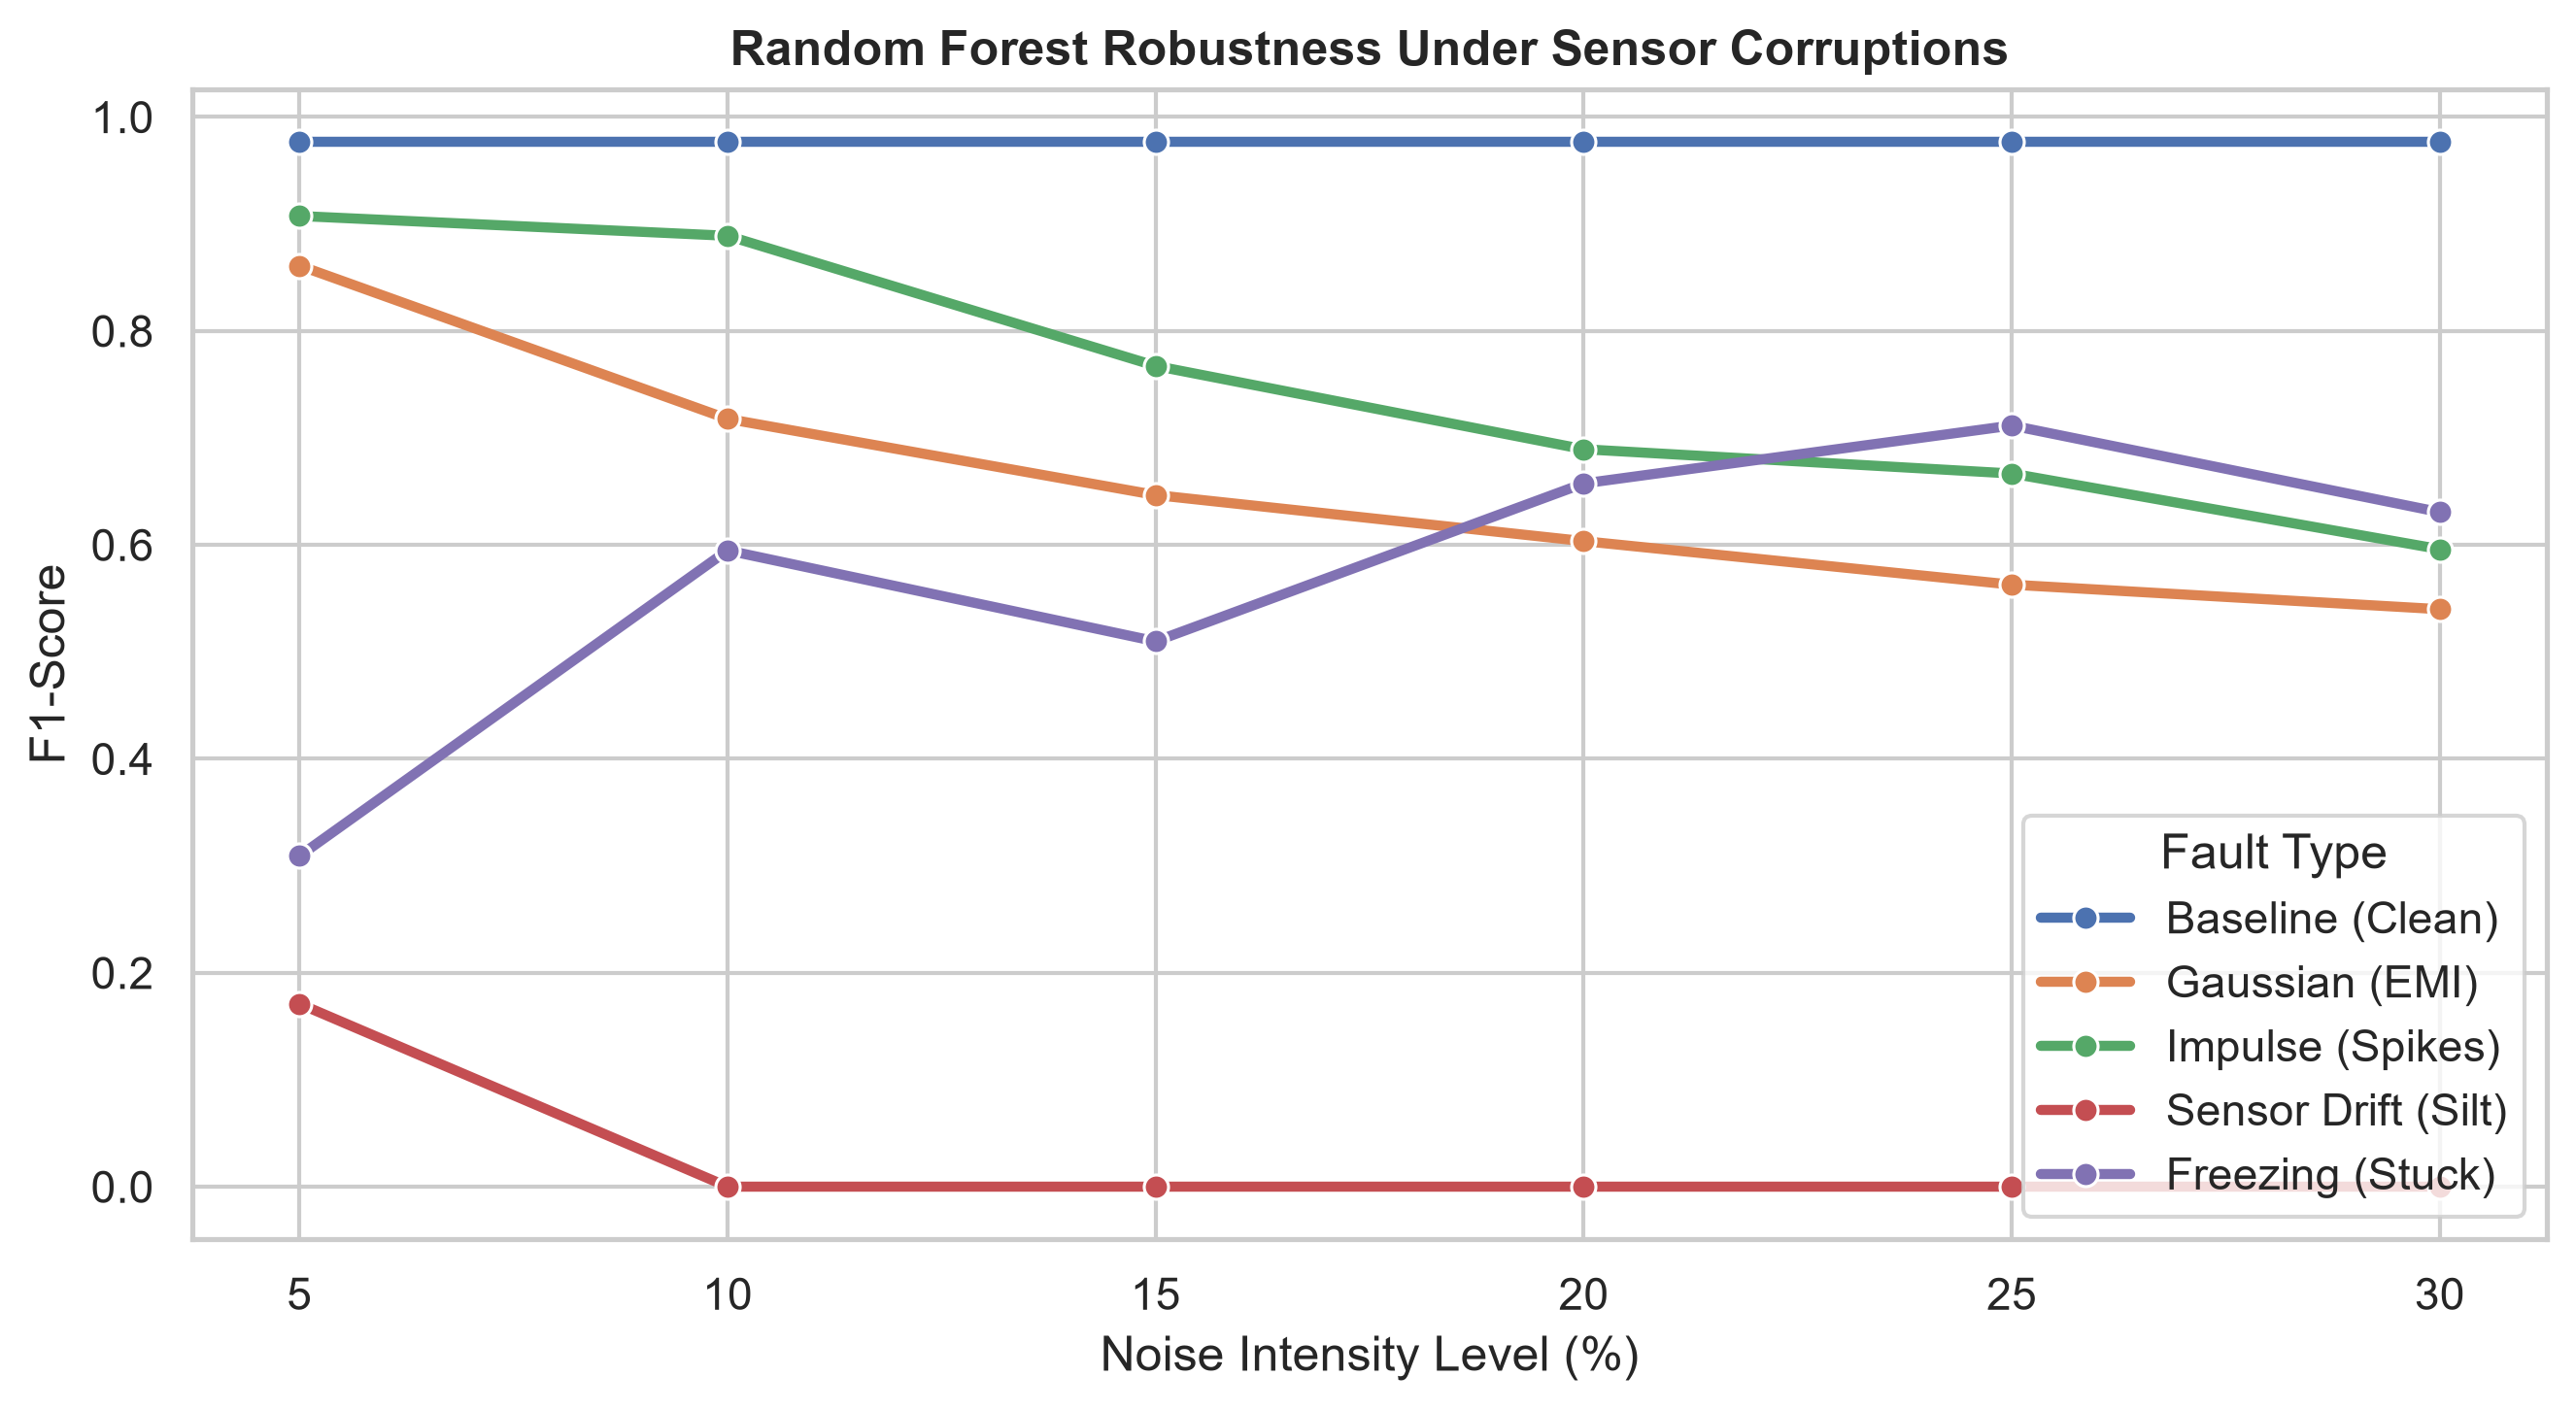

In [4]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5), dpi=300)

if (
    "noise_level" in df_results.columns
    and "f1_score" in df_results.columns
    and "fault_type" in df_results.columns
):
    sns.lineplot(
        data=df_results,
        x="noise_level",
        y="f1_score",
        hue="fault_type",
        marker="o",
        linewidth=2.5,
    )

    plt.title(
        "Random Forest Robustness Under Sensor Corruptions",
        fontsize=12,
        fontweight="bold",
    )
    plt.xlabel("Noise Intensity Level (%)")
    plt.ylabel("F1-Score")
    plt.legend(title="Fault Type")
    plt.tight_layout()

    plt.savefig("reports/Figure_4_2_Degradation_Curves.png", dpi=300)
    plt.show()
else:
    print("Columns available in CSV:", df_results.columns.tolist())